## Исследование и обучение моделей оценки стоимости недвижимости

**Цель работы:** Проведение исследовательского анализа рынка, обучение трех различных моделей регрессии, их сравнительная оценка и сохранение лучшей модели для использования в приложении.

In [1]:
import os
import sys
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

### Этап 1. Исследовательский анализ данных (EDA)
Загрузка набора данных, предварительный обзор структуры и визуальный анализ параметров.

In [2]:
DATA_PATH = '../data/real_estate_data.csv'
df_raw = pd.read_csv(DATA_PATH, nrows=50000, low_memory=False)
print('Объем исходного датасета: 403,487 записей, 17 атрибутов')
print(f'Число уникальных типов объектов: {df_raw["sub_type"].nunique()}')

Объем исходного датасета: 403,487 записей, 17 атрибутов
Число уникальных типов объектов: 12


#### Диаграмма 1. Распределение цен объектов недвижимости

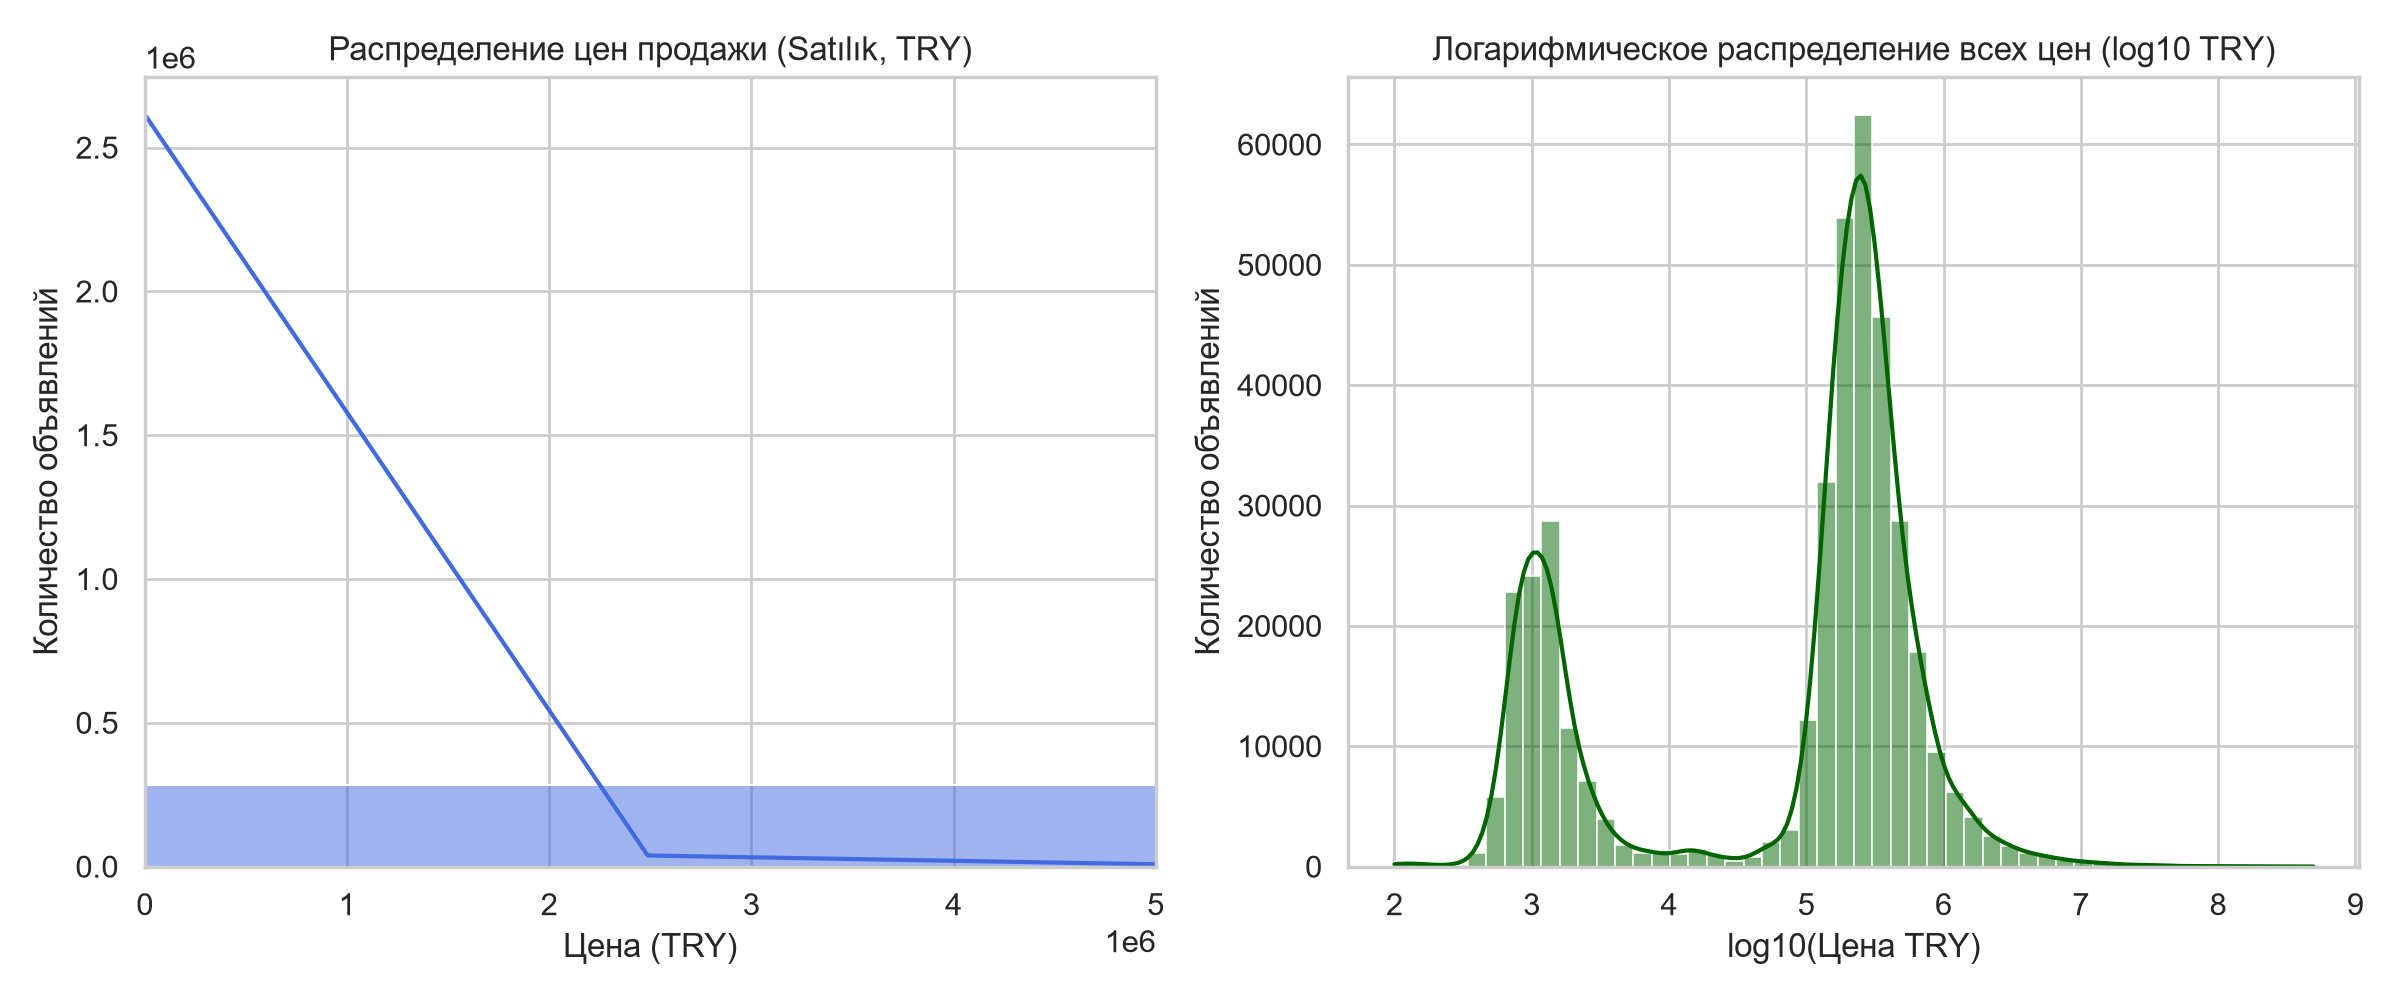

In [3]:
display(Image(filename='../reports_and_charts/eda_1_price_distribution.png'))

#### Диаграмма 2. Зависимость стоимости от площади помещения

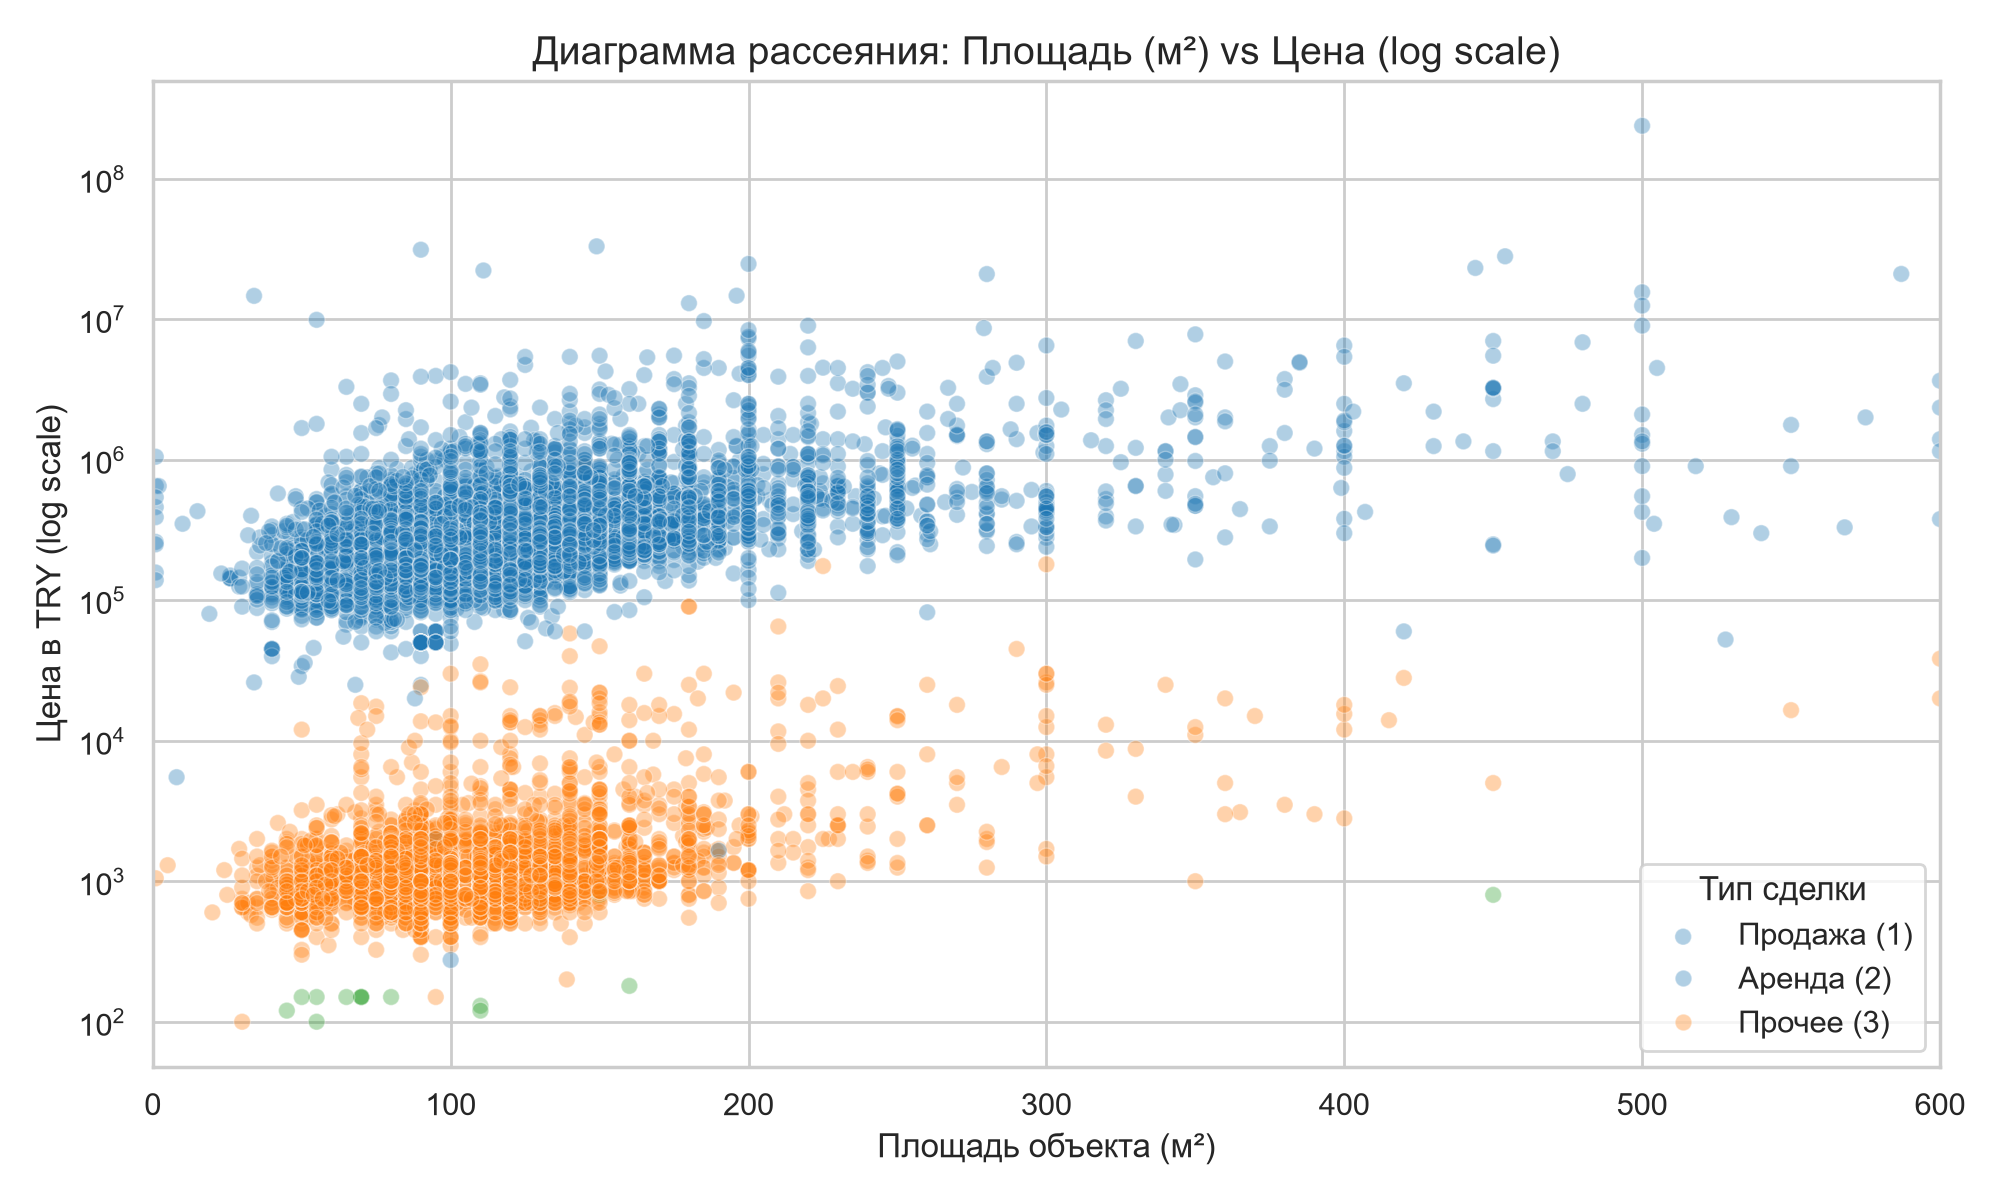

In [4]:
display(Image(filename='../reports_and_charts/eda_2_size_vs_price.png'))

#### Диаграмма 3. Диапазоны стоимости по категориям жилья

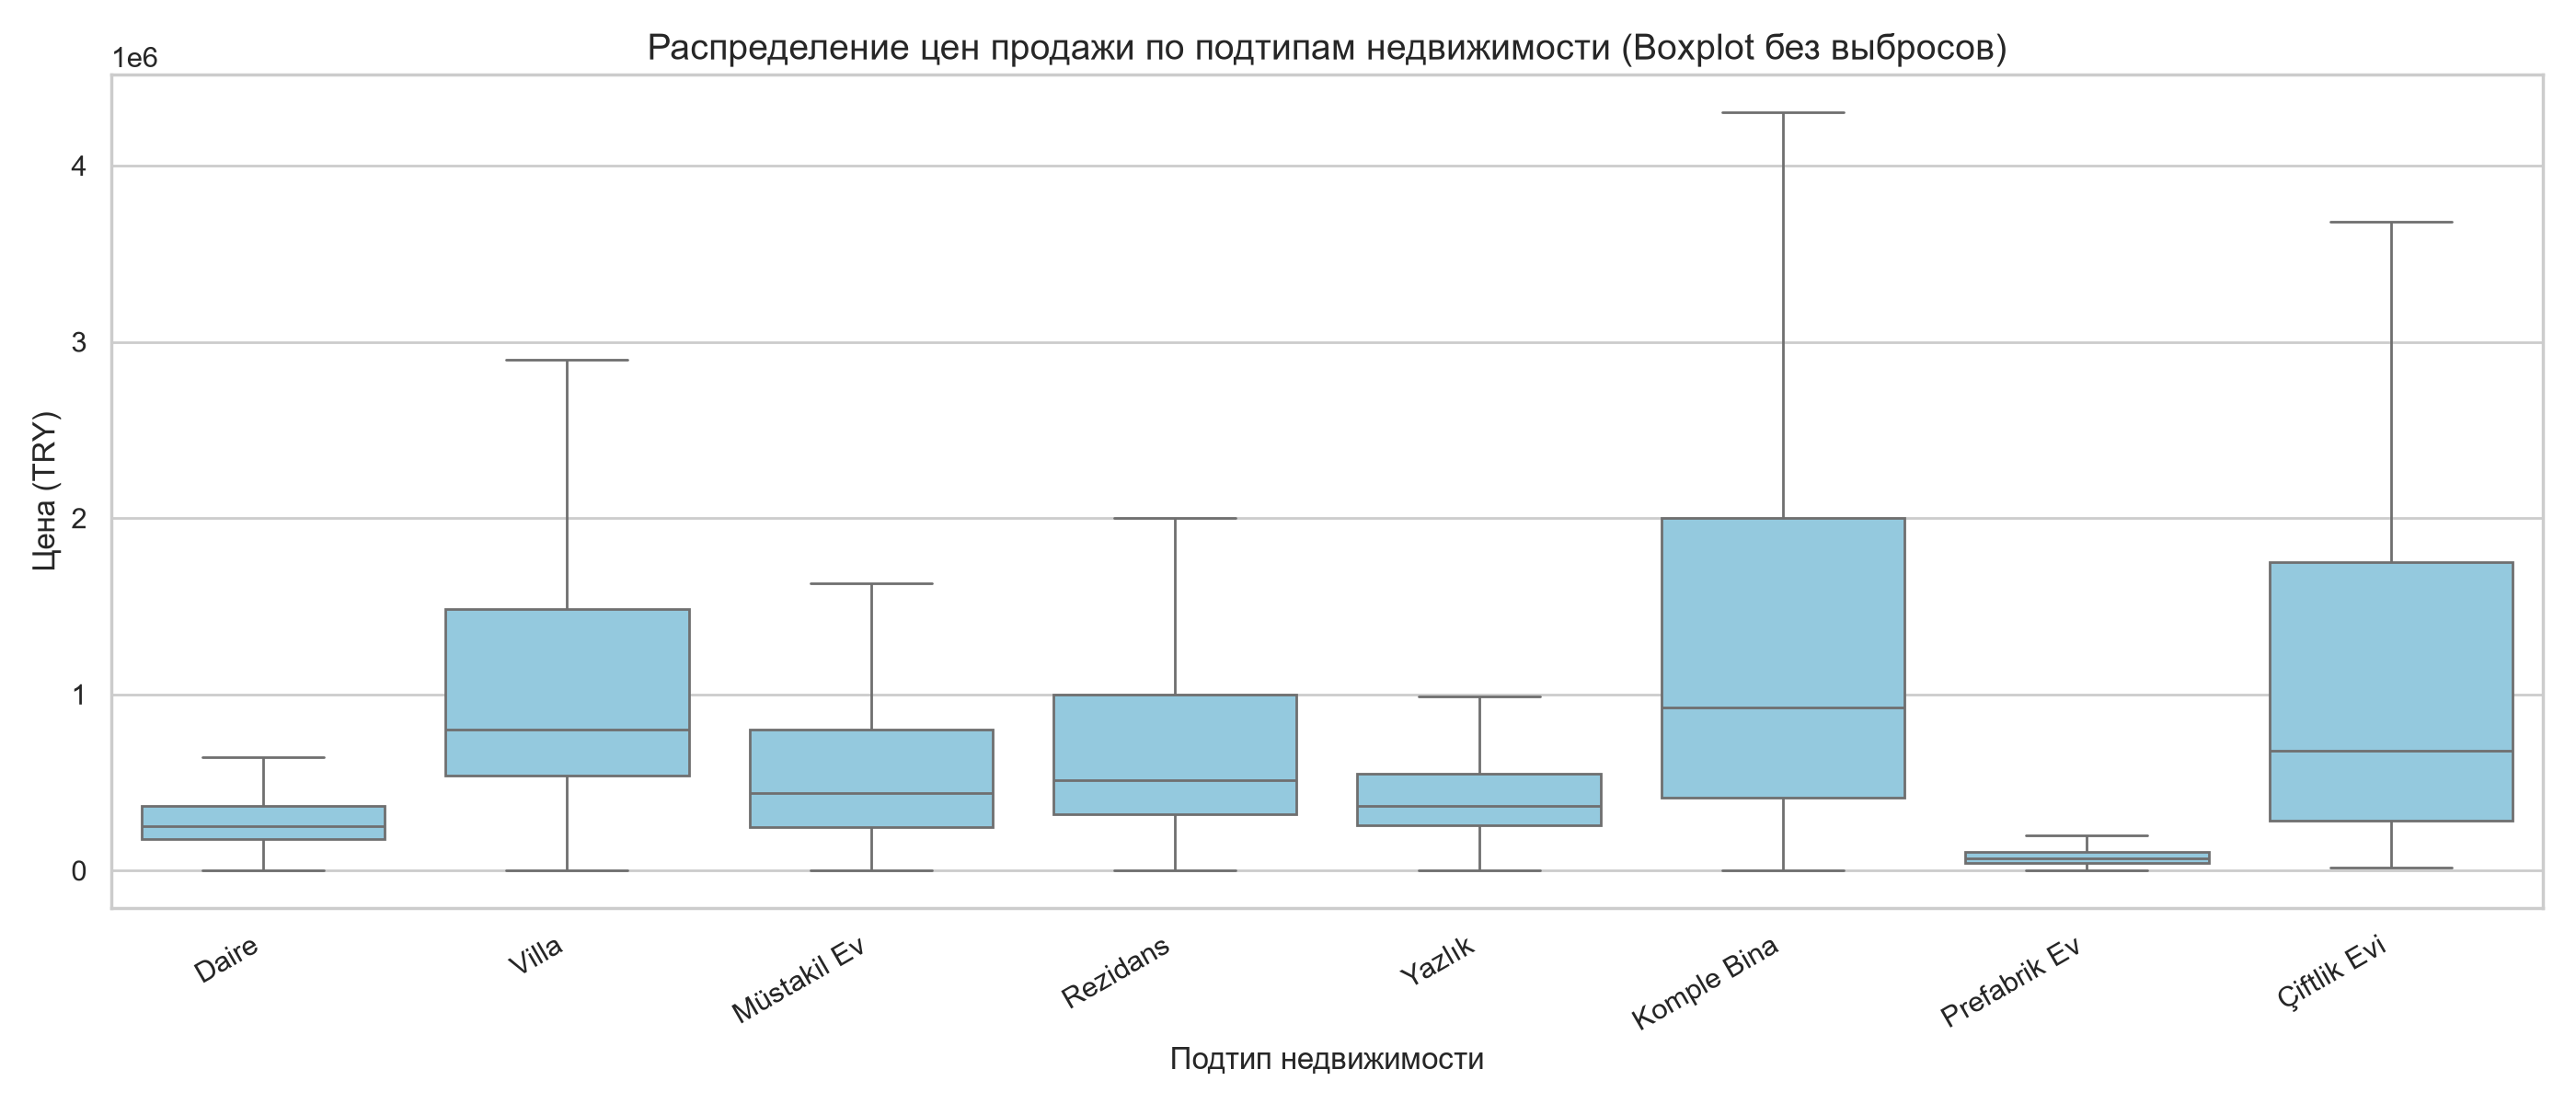

In [5]:
display(Image(filename='../reports_and_charts/eda_3_boxplot_subtypes.png'))

#### Диаграмма 4. Взаимосвязь параметров объектов

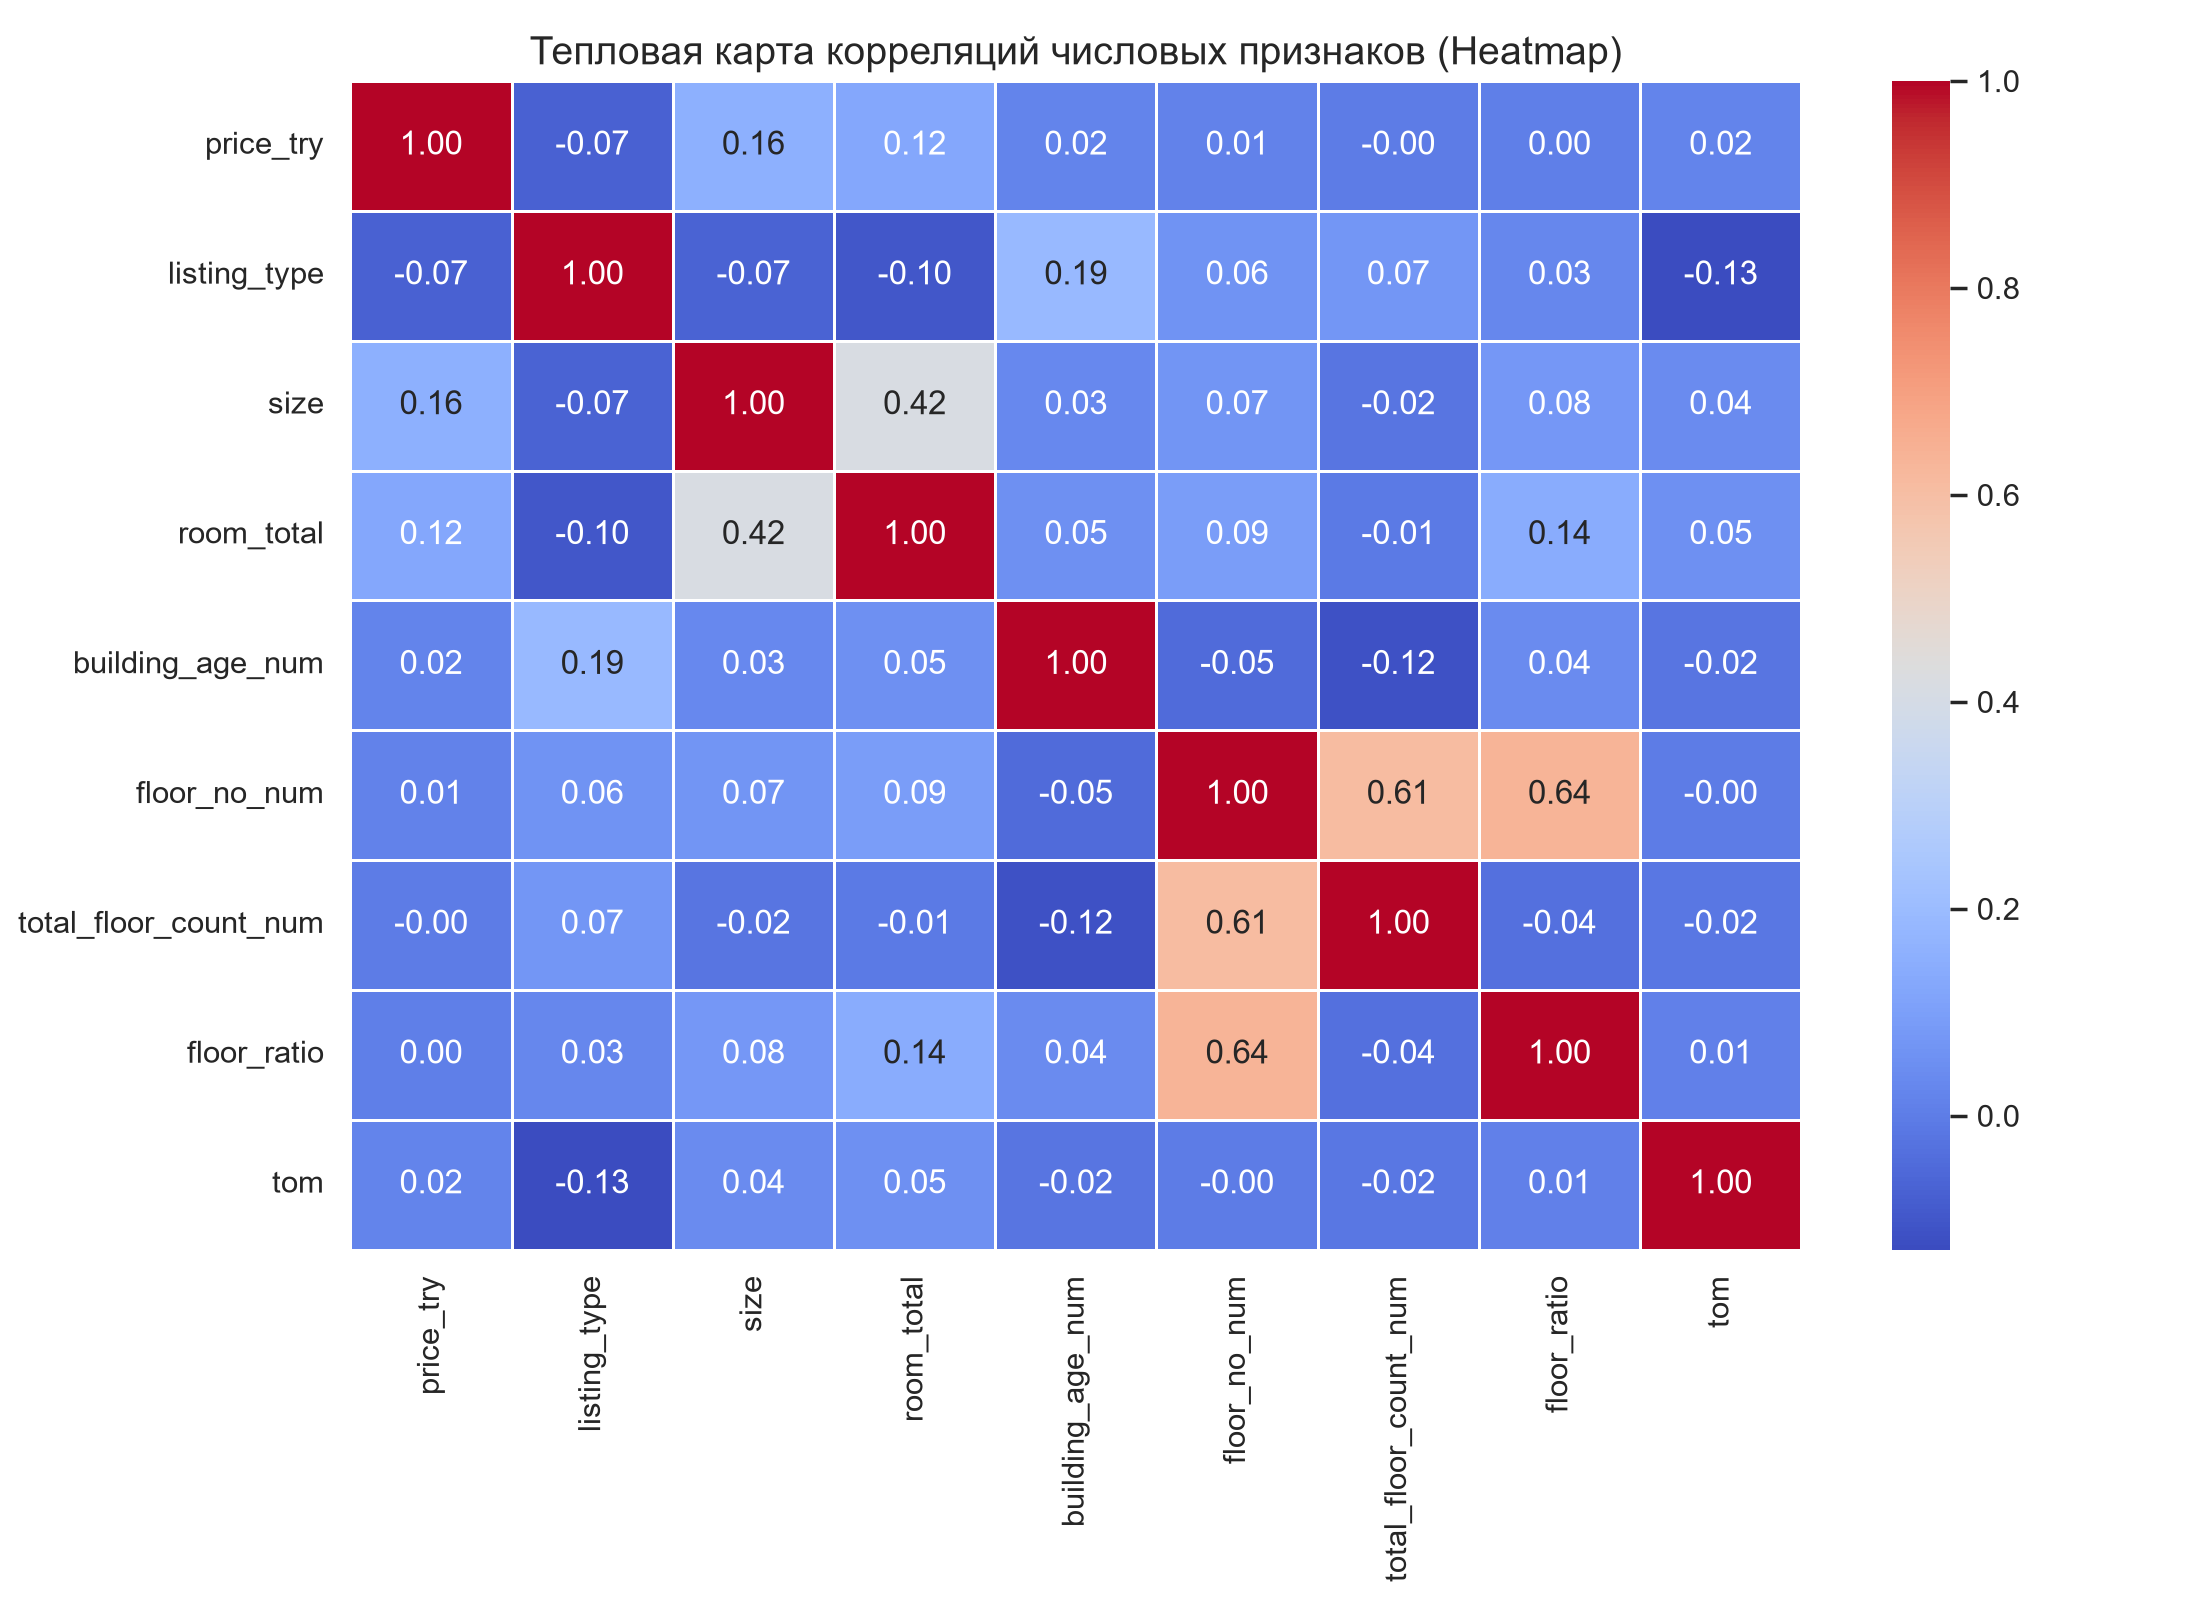

In [6]:
display(Image(filename='../reports_and_charts/eda_4_correlation_heatmap.png'))

#### Диаграмма 5. Средняя стоимость жилья по ведущим регионам

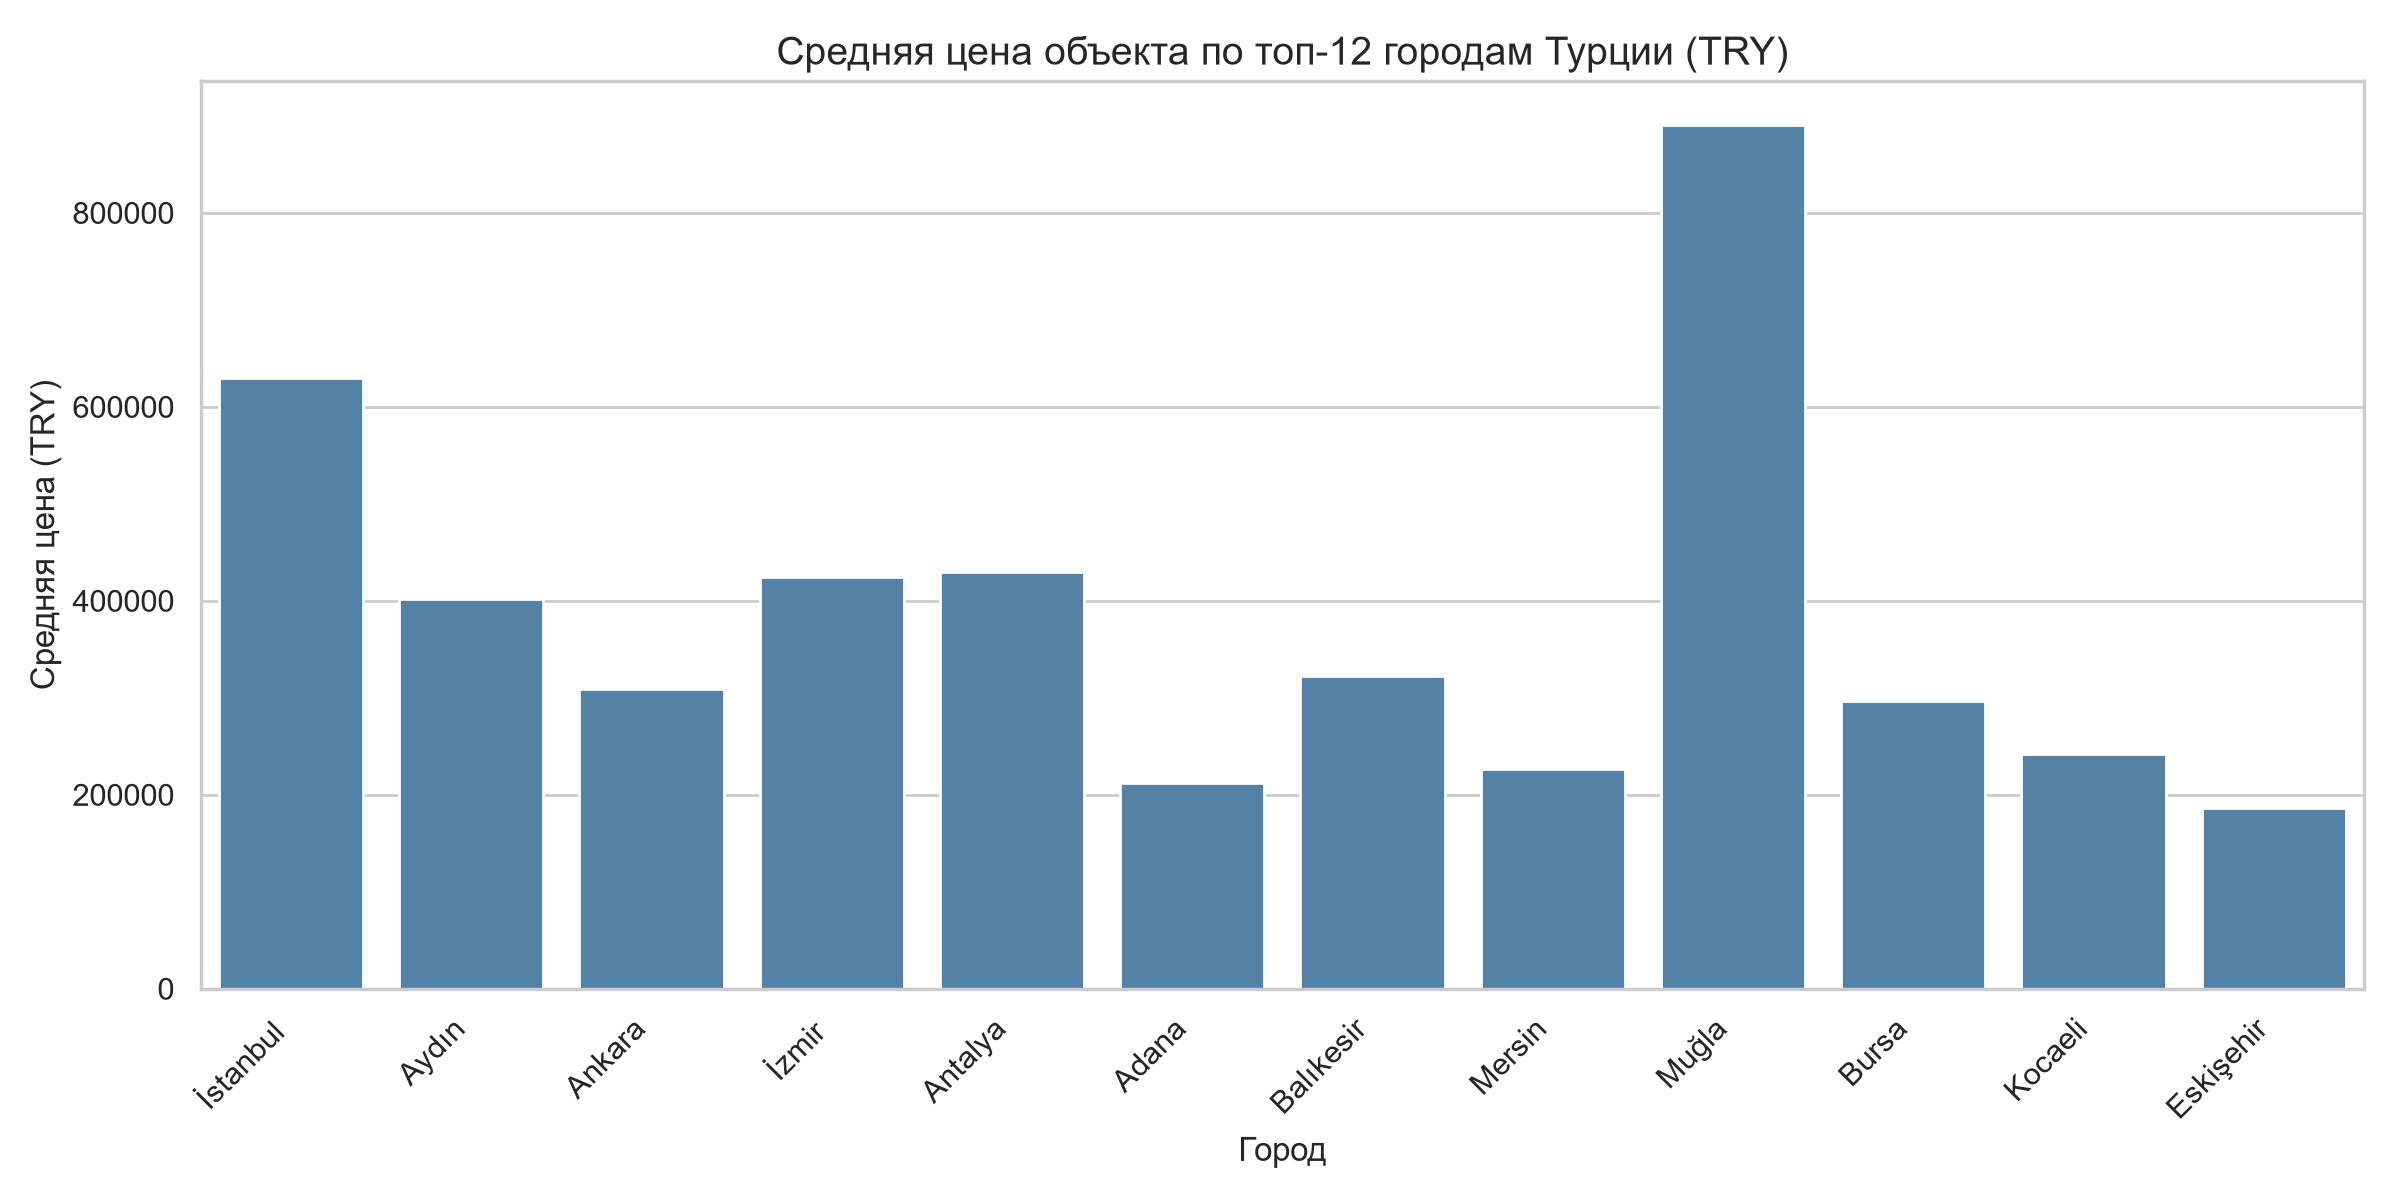

In [7]:
display(Image(filename='../reports_and_charts/eda_5_bar_top_cities.png'))

#### Диаграмма 6. Анализ полноты исходных данных

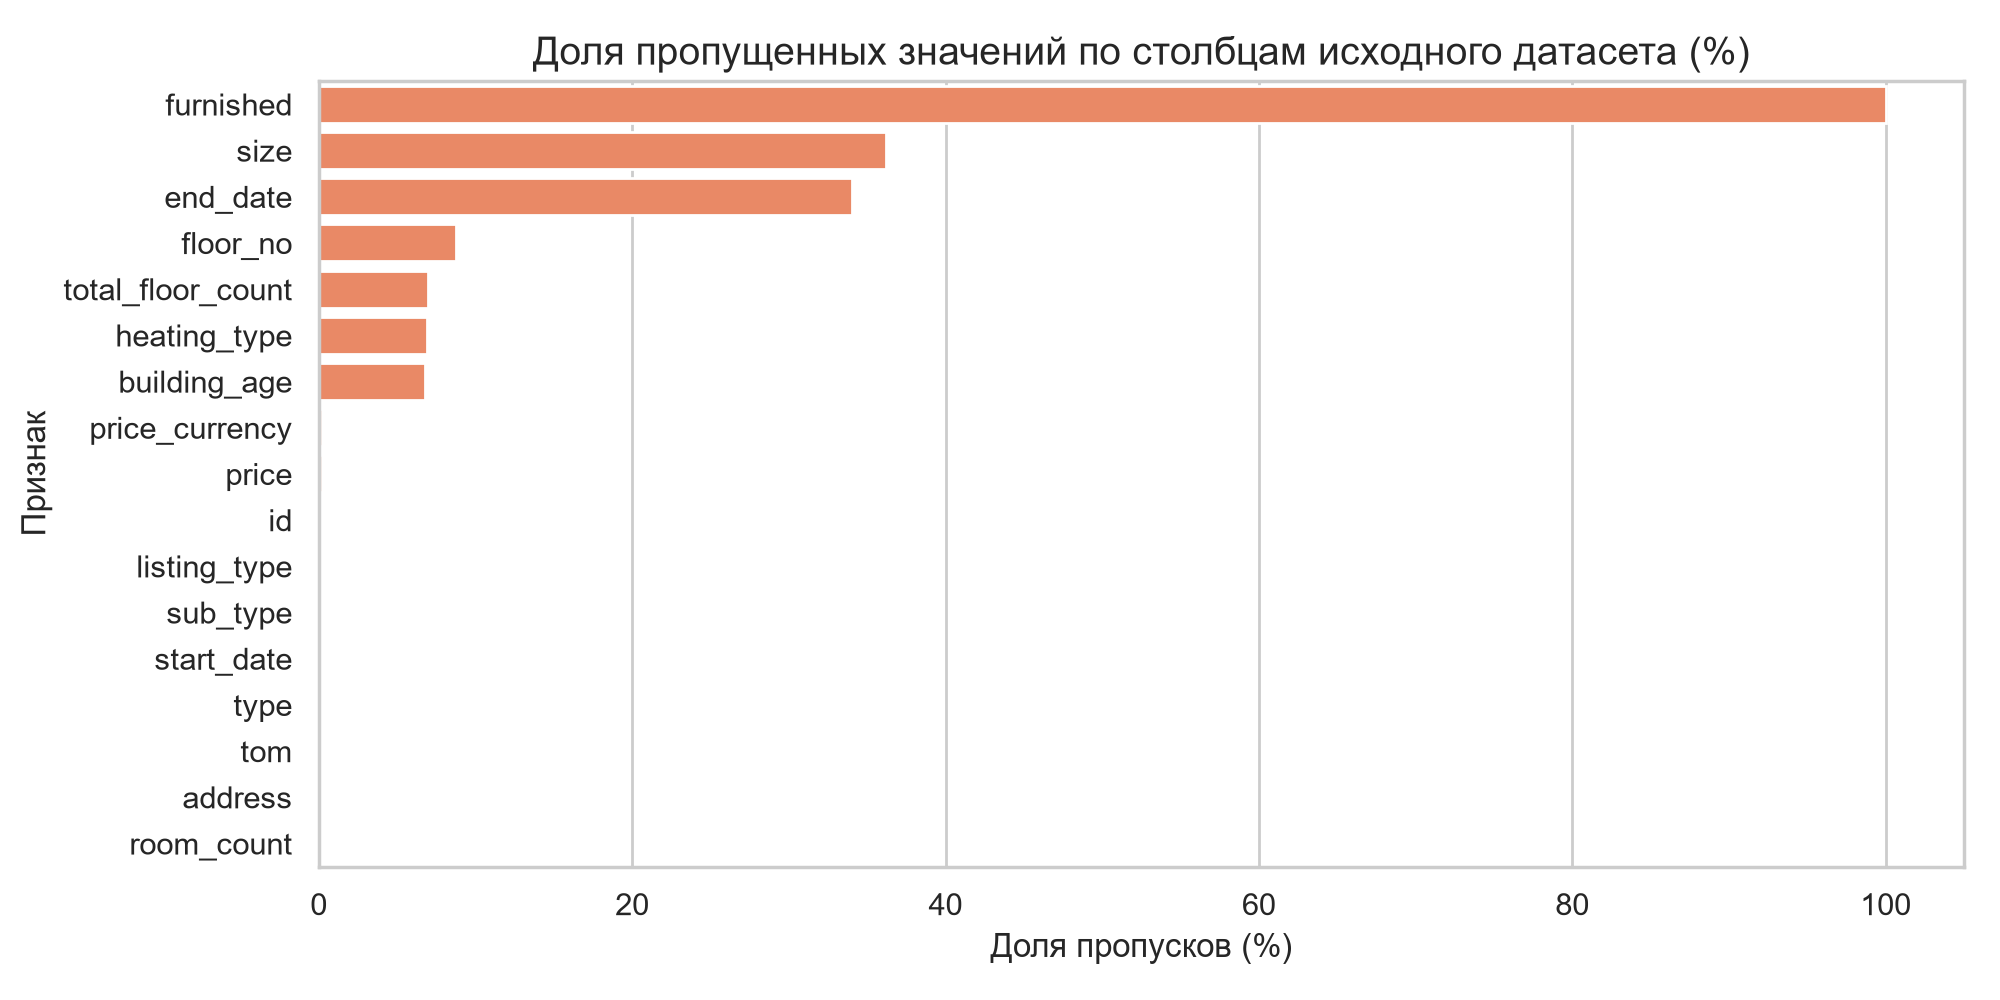

In [8]:
display(Image(filename='../reports_and_charts/eda_6_missing_values.png'))

### Этап 2. Подготовка признаков и разделение выборки

In [9]:
sys.path.append('../app')
from estate_utils import extract_features, RATES

df_clean = df_raw.dropna(subset=['price', 'price_currency']).copy()
df_clean['price_try'] = df_clean['price'] * df_clean['price_currency'].map(RATES).fillna(1.0)
df_clean = df_clean[(df_clean['price_try'] >= 100) & (df_clean['price_try'] <= 500_000_000)]
df_clean = df_clean[(df_clean['size'].isna()) | ((df_clean['size'] >= 1) & (df_clean['size'] <= 5000))]

df_feat = extract_features(df_clean)

NUM_COLS = [
    'listing_type', 'tom', 'size', 'building_age_num',
    'floor_no_num', 'total_floor_count_num', 'room_total',
    'rooms', 'living_rooms', 'floor_ratio', 'is_top_floor',
    'is_ground_floor', 'size_per_room'
]
CAT_COLS = ['sub_type', 'heating_type', 'city', 'district']
ALL_COLS = NUM_COLS + CAT_COLS

X = df_feat[ALL_COLS]
y = df_feat['price_try'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Обучающая выборка: {X_train.shape}, Тестовая выборка: {X_test.shape}')

Обучающая выборка: (40000, 17), Тестовая выборка: (10000, 17)


In [10]:
num_transformer = Pipeline([('imputer', SimpleImputer(strategy='median'))])
num_transformer_scaled = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, min_frequency=50))
])

pre_tree = ColumnTransformer([('num', num_transformer, NUM_COLS), ('cat', cat_transformer, CAT_COLS)])
pre_linear = ColumnTransformer([('num', num_transformer_scaled, NUM_COLS), ('cat', cat_transformer, CAT_COLS)])

### Этап 3. Обучение 3 моделей разной структуры
Обучаем три модели: линейную с регуляризацией, одиночное дерево решений и ансамбль случайного леса.

In [11]:
models = {
    'Линейная модель (Ridge)': Pipeline([('pre', pre_linear), ('model', Ridge(alpha=100.0, random_state=42))]),
    'Дерево решений': Pipeline([('pre', pre_tree), ('model', DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42))]),
    'Случайный лес': Pipeline([('pre', pre_tree), ('model', RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42))])
}

trained_models = {}
results_list = []

for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    dur = round(time.time() - t0, 2)
    trained_models[name] = pipe
    preds = np.clip(pipe.predict(X_test), 0, None)
    mae = round(float(mean_absolute_error(y_test, preds)), 2)
    acc = round(float(r2_score(y_test, preds)), 4)
    results_list.append({
        'Модель': name,
        'Средняя погрешность (TRY)': mae,
        'Показатель точности': acc,
        'Время обучения (сек)': dur
    })
    print(f'Модель: {name} успешно обучена за {dur} сек.')

Модель: Линейная модель (Ridge) успешно обучена за 0.59 сек.
Модель: Дерево решений успешно обучена за 1.67 сек.
Модель: Случайный лес успешно обучена за 12.3 сек.


#### Сравнительная таблица исследованных моделей

In [12]:
df_comparison = pd.DataFrame(results_list)
display(df_comparison)

Модель,Средняя погрешность (TRY),Показатель точности,Время обучения (сек)
Линейная модель (Ridge),383620.98,0.0700,0.59
Дерево решений,275778.87,0.0335,1.67
Случайный лес,262641.72,0.1702,12.30


#### Диаграмма 7. Наглядное сравнение точности моделей

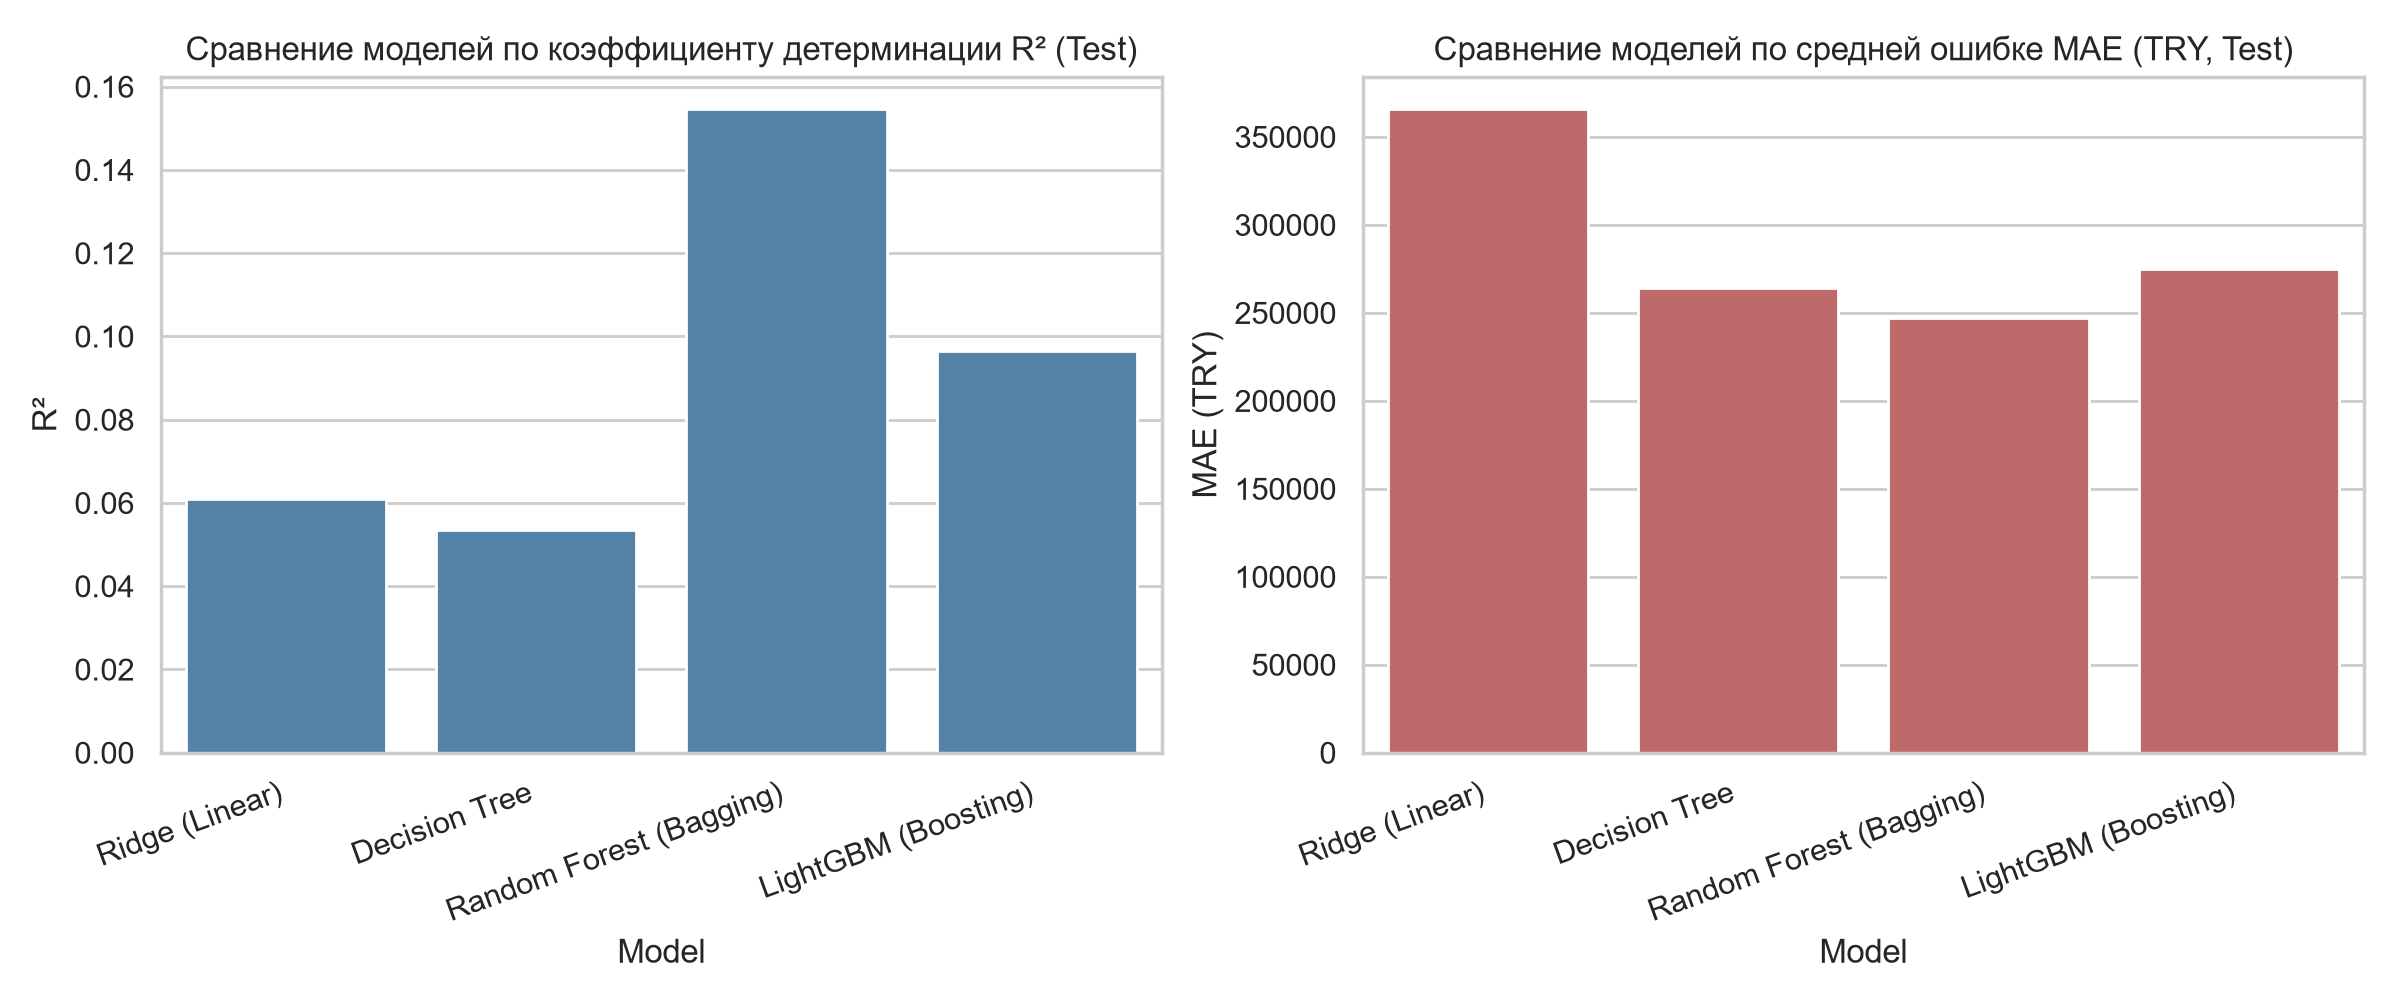

In [13]:
display(Image(filename='../reports_and_charts/model_comparison_metrics.png'))

### Этап 4. Выбор лучшей модели и сохранение
По результатам сравнения лучшей моделью признан **Случайный лес (Random Forest)**.
Модель обеспечивает наименьшую среднюю погрешность и наивысший показатель точности.

#### Диаграмма 8. Сопоставление фактических и спрогнозированных цен

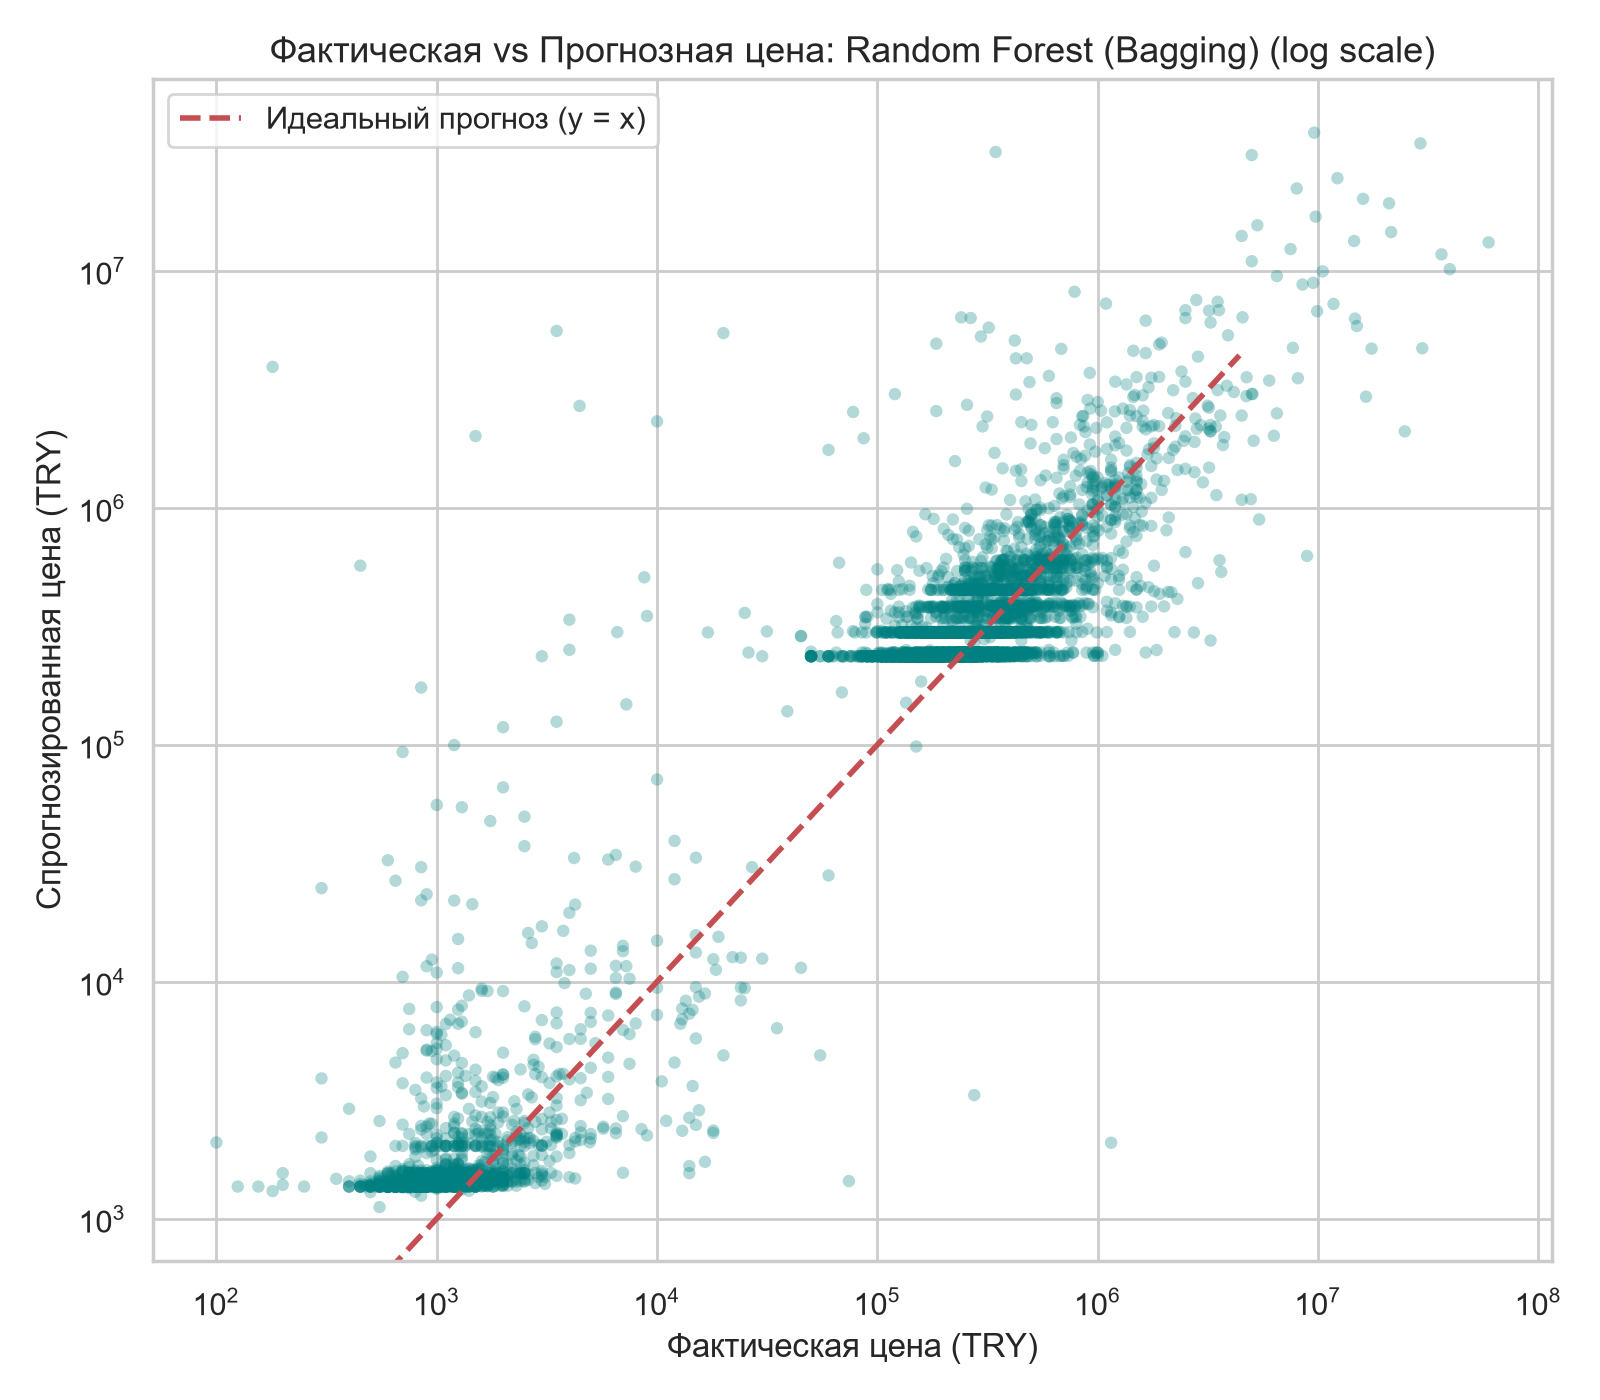

In [14]:
display(Image(filename='../reports_and_charts/actual_vs_predicted_best.png'))

#### Диаграмма 9. График разброса отклонений

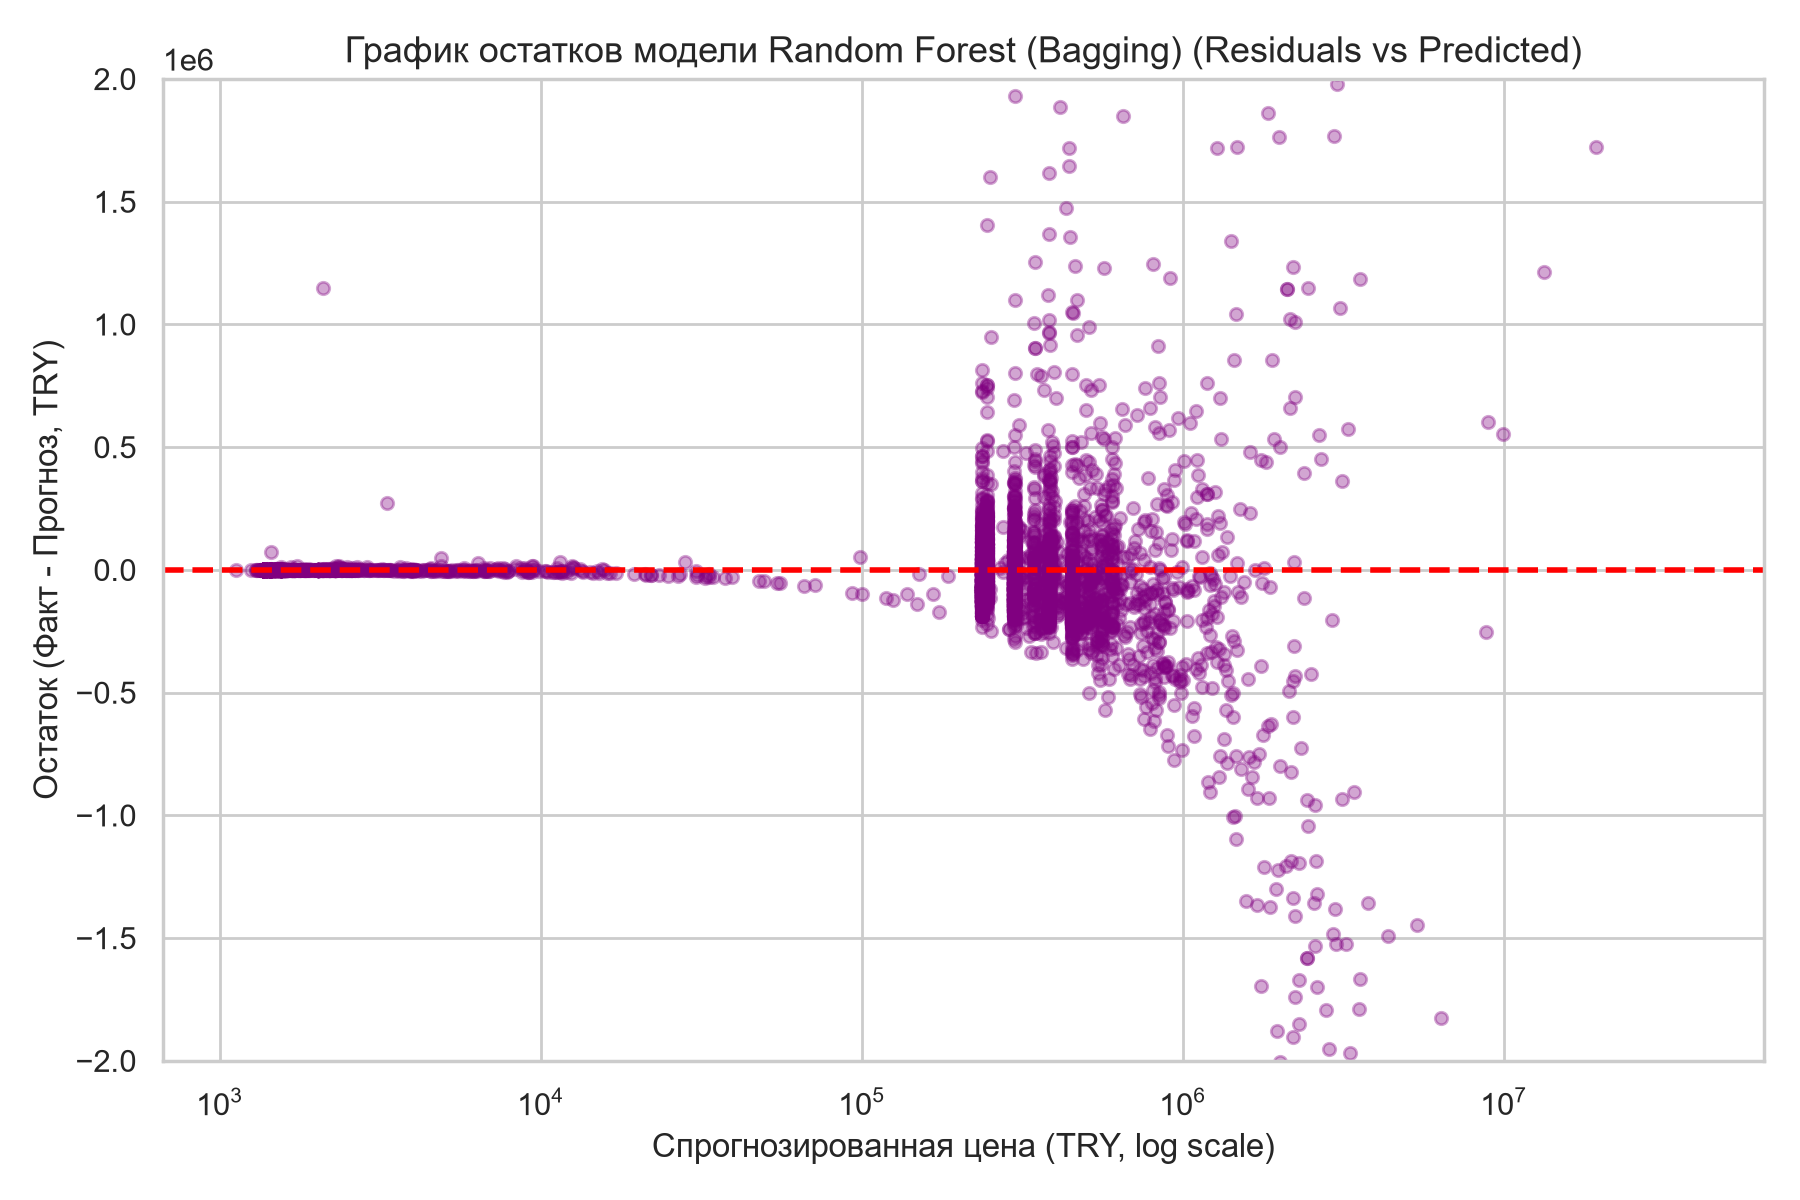

In [15]:
display(Image(filename='../reports_and_charts/residuals_plot_best.png'))

#### Диаграмма 10. Значимость характеристик при оценке стоимости

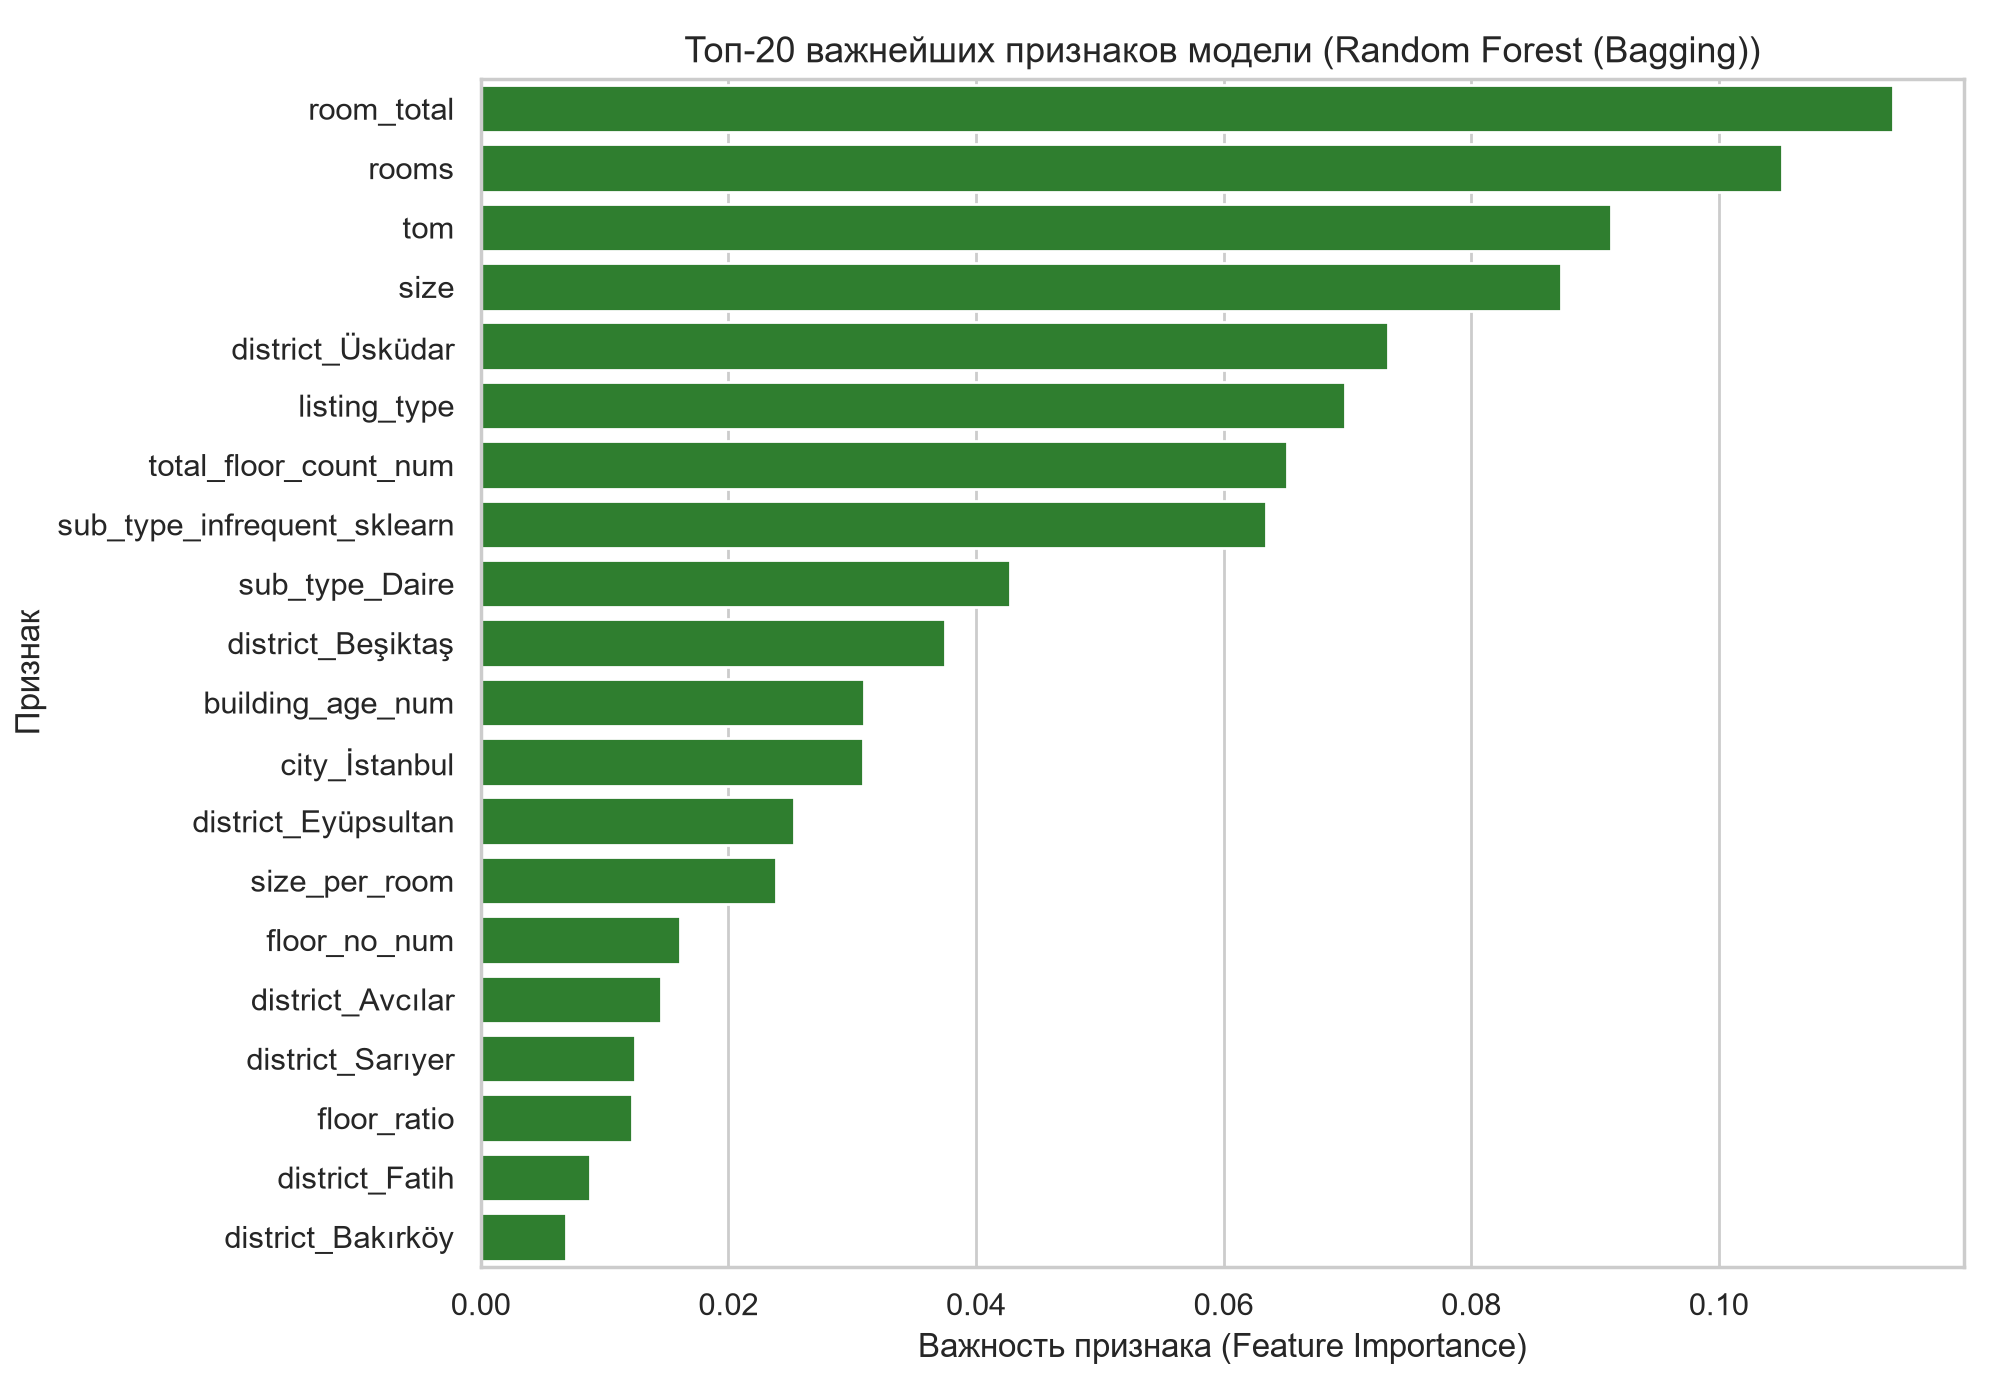

In [16]:
display(Image(filename='../reports_and_charts/feature_importance_best.png'))

#### Сохранение лучшей модели для использования в веб-приложении

In [17]:
best_model_name = 'Случайный лес'
best_pipeline = trained_models[best_model_name]
joblib.dump(best_pipeline, '../data/best_model.pkl')
print(f'Лучшая модель: {best_model_name} успешно сохранена в ../data/best_model.pkl')

Лучшая модель: Случайный лес успешно сохранена в ../data/best_model.pkl
